# Audit diagnostics and independent verification

This notebook separates findings from evidence of failure. It reruns diagnostics on real unchanged Adult records, compares threshold sensitivity, and verifies near matches with an independent algorithm.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, io, contextlib
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/leakage_audit/audit.py').exists()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
RUN = ROOT / 'data/interim' / ('analysis-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
RUN.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Fresh analysis directory:', RUN.relative_to(ROOT))
from collections import Counter
from collections import Counter

Fresh analysis directory: data\interim\analysis-20261016T080453622679Z


In [2]:
from leakage_audit.adult_validation import validate
from leakage_audit import read_csv
from leakage_audit.audit import missing, audit, AuditConfig
with contextlib.redirect_stdout(io.StringIO()): validate(report=RUN / 'adult-source.json')
train = read_csv('data/processed/adult/train.csv')
test = read_csv('data/processed/adult/test.csv')
print({'train':len(train), 'heldout':len(test), 'columns':len(train[0])})

{'train': 32561, 'heldout': 16281, 'columns': 15}


## Independent near-match oracle
The package uses projection hashing. The reference sorts projections and scans groups. Agreement checks implementation correctness, not whether matches are harmful.

In [3]:
from leakage_audit.near_validation import validate as verify_near
with contextlib.redirect_stdout(io.StringIO()):
    verification=verify_near(report=RUN/'independent-near.json')
assert verification['independent_sorted_reference_agrees']
print({k:verification[k] for k in ['rows','independent_sorted_reference_agrees','default_findings_unchanged']})
print('Unique heldout near matches:',verification['near_matches']['test_rows'])

{'rows': {'train': 32561, 'test': 16281}, 'independent_sorted_reference_agrees': True, 'default_findings_unchanged': True}
Unique heldout near matches: 3032


## Shift-threshold sensitivity
Thresholds control review volume. A low threshold can flag small natural split differences. The sweep does not tune an accuracy score because no leakage ground truth exists.

[
  {
    "threshold": 0.005,
    "numeric_shift": 2,
    "categorical_shift": 6,
    "all_findings": 9
  },
  {
    "threshold": 0.01,
    "numeric_shift": 0,
    "categorical_shift": 2,
    "all_findings": 3
  },
  {
    "threshold": 0.02,
    "numeric_shift": 0,
    "categorical_shift": 0,
    "all_findings": 1
  },
  {
    "threshold": 0.05,
    "numeric_shift": 0,
    "categorical_shift": 0,
    "all_findings": 1
  },
  {
    "threshold": 0.1,
    "numeric_shift": 0,
    "categorical_shift": 0,
    "all_findings": 1
  },
  {
    "threshold": 0.3,
    "numeric_shift": 0,
    "categorical_shift": 0,
    "all_findings": 1
  }
]


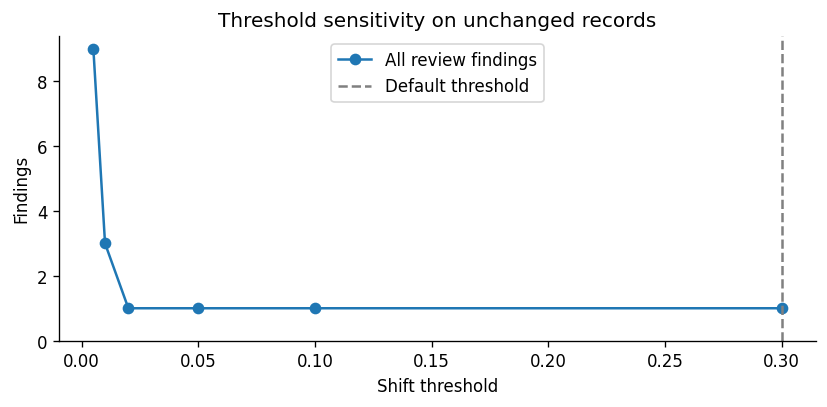

In [4]:
thresholds=[.005,.01,.02,.05,.1,.3]
summaries=[]
for threshold in thresholds:
    report=audit(train,test,AuditConfig('target',shift_threshold=threshold))
    kinds=Counter(f['kind'] for f in report['findings'])
    summaries.append({'threshold':threshold,'numeric_shift':sum(f['kind']=='distribution_shift' and f['evidence'].get('method')=='empirical_ks' for f in report['findings']),'categorical_shift':sum(f['kind']=='distribution_shift' and f['evidence'].get('method')=='total_variation' for f in report['findings']),
                      'all_findings':len(report['findings'])})
print(json.dumps(summaries,indent=2))
fig,ax=plt.subplots(figsize=(7,3.5))
ax.plot(thresholds,[r['all_findings'] for r in summaries],marker='o',label='All review findings')
ax.set(xlabel='Shift threshold',ylabel='Findings',ylim=(0,None),title='Threshold sensitivity on unchanged records')
ax.axvline(.3,color='gray',linestyle='--',label='Default threshold');ax.legend()
fig.tight_layout();fig.savefig(RUN/'threshold-sensitivity.png');plt.show()

## Explicit target-quality inspection
Default auditing ignores heldout target values. This separate opt-in call examines missing or contradictory labels and labels the added signals as quality reviews.

Additional opt-in findings: {'within_train_label_conflicts': 1, 'cross_split_label_conflicts': 1}


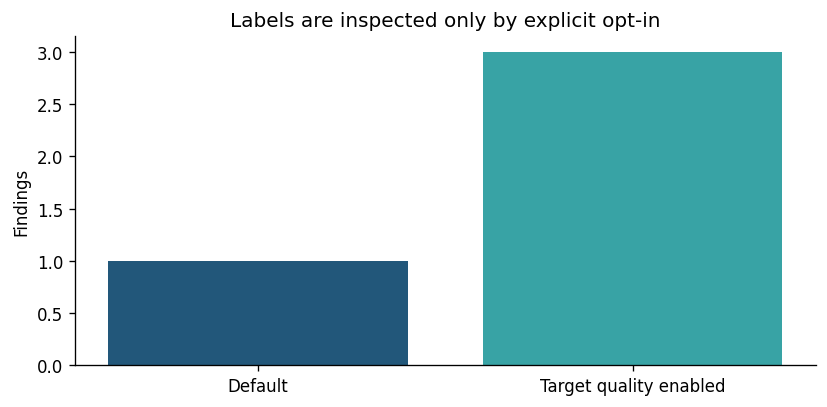

839

In [5]:
standard=audit(train,test,AuditConfig('target'))
quality=audit(train,test,AuditConfig('target',check_target_quality=True))
standard_kinds=Counter(f['kind'] for f in standard['findings'])
quality_kinds=Counter(f['kind'] for f in quality['findings'])
added=quality_kinds-standard_kinds
print('Additional opt-in findings:',dict(added))
fig,ax=plt.subplots(figsize=(7,3.5))
ax.bar(['Default','Target quality enabled'],[len(standard['findings']),len(quality['findings'])],color=['#22577a','#38a3a5'])
ax.set(ylabel='Findings',title='Labels are inspected only by explicit opt-in')
fig.tight_layout();fig.savefig(RUN/'target-quality.png');plt.show()
(RUN/'diagnostics.json').write_text(json.dumps({'thresholds':summaries,'added_target_checks':dict(added)},indent=2))

## Limits
Independent algorithms agree on the counts, but Adult cannot supply person-identity or harmful-leakage ground truth. The earlier constructed software checks remain tests of mechanics, not real-world sensitivity. Exact numeric normalization is opt-in and does not imply fuzzy identity matching. See Report.md for the interpretation and reproduction commands.